# PSD PREDICTION ANALYSIS

In [11]:
import matplotlib.pyplot as plt  # type: ignore
import numpy as np  # type: ignore
import os
import pandas as pd  # type: ignore
from typing import Optional, cast, List, Union

import src.constants as cn
from src.psd_prediction_file_iterator import PSDPredictionFileIterator
from src.psd_prediction_analyzer import PSDPredictionAnalyzer
from src.nl_curve import NLCurve
from src.piecewise_system_discovery import PiecewiseSystemDiscovery

# Data analysis

In [2]:
def fileFilter(dct) -> bool:
    if not "maxreduction" in dct:
        return False
    if dct["maxreduction"] !=  1e-5:
        pass
        #return False
    if dct["repeat"] > 1:
        pass
        #return False
    return True



In [3]:
def dataframeFilter(df, dct) -> pd.DataFrame:
    new_df = df.copy()
    return new_df[ new_df [cn.COL_AGGREGATION_TYPE] == "model"]

In [4]:
df = PSDPredictionFileIterator.query(file_filter=fileFilter, data_frame_filter=dataframeFilter,
        is_guard_filename=True)
#df = df [ df[cn.COL_SYSTEM_ID] == "BIOMD0000000297"]
df = df.reset_index()
df[[cn.COL_SYSTEM_ID, cn.COL_P50, cn.COL_AUC, cn.COL_NUM_CHANGEPOINT]]

,system_id,p50,auc,num_changepoint
0,BIOMD0000000005,0.950792,0.972043,880
1,BIOMD0000000010,0.864240,0.997727,2219
2,BIOMD0000000042,0.969149,0.996254,2810
3,BIOMD0000000234,0.386742,0.468664,47
4,BIOMD0000000278,1.000000,0.999800,5000
...,...,...,...,...
8592,BIOMD0000001056,0.887416,0.879896,2168
8593,BIOMD0000001057,0.499990,0.597396,1732
8594,BIOMD0000001058,0.999633,0.999762,4922
8595,BIOMD0000001059,0.997745,0.924847,3520


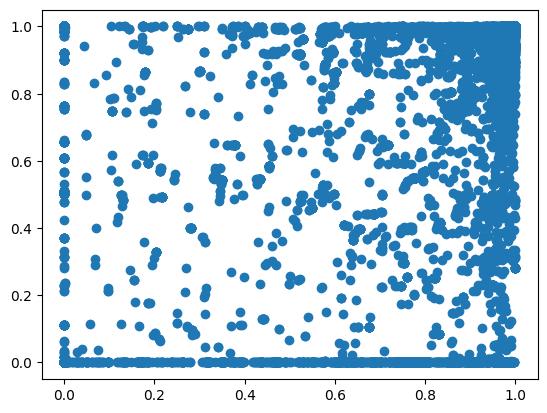

In [5]:
plt.scatter(df[cn.COL_AUC].values, df[cn.COL_P50].values)

In [6]:
#df.loc[df.groupby('A')['B'].idxmin(), ['A', 'B', 'C']]
df1 = df[df[cn.COL_P50] > 0.8]
dff = df1.loc[df1.groupby(cn.COL_SYSTEM_ID)[cn.COL_AUC].idxmin(),[cn.COL_SYSTEM_ID, cn.COL_NUM_CHANGEPOINT, cn.COL_AUC, cn.COL_P50, cn.COL_FILENAME]]
dff

,system_id,num_changepoint,auc,p50,filename
1938,BIOMD0000000005,121,0.895795,0.841488,piecewise_predictions__numpoint_100000__thresh...
1525,BIOMD0000000010,1741,0.995949,0.807855,piecewise_predictions__numpoint_100000__thresh...
267,BIOMD0000000042,314,0.984928,0.834115,piecewise_predictions__numpoint_100000__thresh...
688,BIOMD0000000234,78,0.930334,0.895649,piecewise_predictions__numpoint_100000__thresh...
269,BIOMD0000000278,0,0.000000,0.999934,piecewise_predictions__numpoint_100000__thresh...
...,...,...,...,...,...
7755,BIOMD0000001055,1769,0.945224,0.994552,piecewise_predictions__numpoint_100000__thresh...
1933,BIOMD0000001056,254,0.666947,0.871495,piecewise_predictions__numpoint_100000__thresh...
3601,BIOMD0000001058,687,0.971053,0.944739,piecewise_predictions__numpoint_100000__thresh...
3186,BIOMD0000001059,1392,0.912866,0.847472,piecewise_predictions__numpoint_100000__thresh...


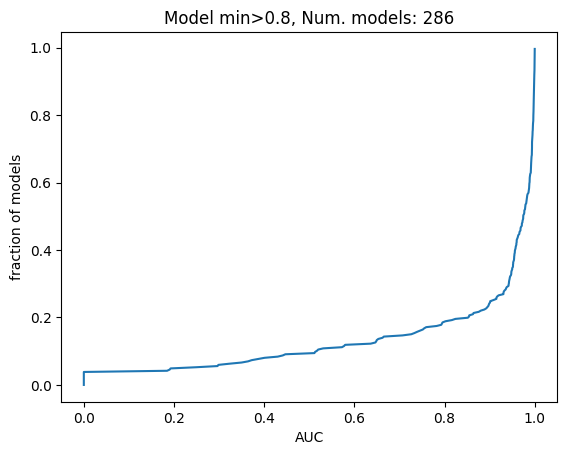

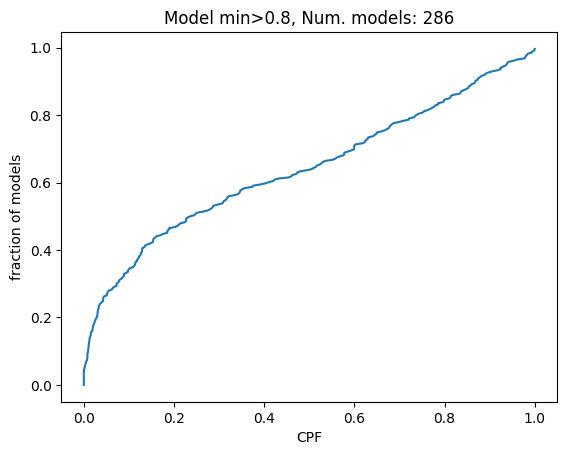

In [7]:
# Parameters
accuracy_threshold = 0.8
statistic = cn.COL_P50
statistic = cn.COL_MIN

# Data construction
df1 = df[df[statistic] > accuracy_threshold]
MODEL_DF = df1.loc[df1.groupby(cn.COL_SYSTEM_ID)[cn.COL_AUC].idxmin(),
    [cn.COL_SYSTEM_ID, cn.COL_NUM_CHANGEPOINT, cn.COL_AUC, cn.COL_P50, cn.COL_MAX, cn.COL_MIN, cn.COL_FILENAME]]
MODEL_DF["CPF"] = MODEL_DF[cn.COL_NUM_CHANGEPOINT] / 5000  # Account for lower max values
num_model = len(MODEL_DF[cn.COL_SYSTEM_ID].unique())
fraction_model = np.array(range(num_model))/num_model

sorted_auc = np.sort(MODEL_DF[cn.COL_AUC].values)
plt.plot(sorted_auc, fraction_model)
title = f"Model {statistic}>{accuracy_threshold}, Num. models: {num_model}"
plt.title(title)
plt.xlabel("AUC")
plt.ylabel("fraction of models")
plt.figure()


sorted_auc = np.sort(MODEL_DF["CPF"].values)
plt.plot(sorted_auc, fraction_model)
title = f"Model {statistic}>{accuracy_threshold}, Num. models: {num_model}"
plt.title(title)
plt.xlabel("CPF")
_ = plt.ylabel("fraction of models")

AUC indicates that there are 3 types of models
* Those that are well approximated by a single linear system
* Those that require a modest to significant number of piecewise approximations
* Those that require a very dense series of piecewise approximations

# Illustration of the different model types

In [10]:
df = MODEL_DF[MODEL_DF["auc"] < 0.01]
df

,system_id,num_changepoint,auc,p50,max,min,filename,CPF
269,BIOMD0000000278,0,0.0,0.999934,0.999978,0.999918,piecewise_predictions__numpoint_100000__thresh...,0.0
344,BIOMD0000000677,0,0.0,0.922101,0.922101,0.922101,piecewise_predictions__numpoint_100000__thresh...,0.0
389,BIOMD0000000736,0,0.0,1.000000,1.000000,1.000000,piecewise_predictions__numpoint_100000__thresh...,0.0
396,BIOMD0000000745,0,0.0,0.983569,0.996122,0.952780,piecewise_predictions__numpoint_100000__thresh...,0.0
449,BIOMD0000000799,0,0.0,0.899953,0.899953,0.899953,piecewise_predictions__numpoint_100000__thresh...,0.0
455,BIOMD0000000807,0,0.0,1.000000,1.000000,1.000000,piecewise_predictions__numpoint_100000__thresh...,0.0
461,BIOMD0000000814,0,0.0,0.989611,0.989611,0.989611,piecewise_predictions__numpoint_100000__thresh...,0.0
522,BIOMD0000000885,0,0.0,1.000000,1.000000,0.999988,piecewise_predictions__numpoint_100000__thresh...,0.0
623,BIOMD0000000994,0,0.0,1.000000,1.000000,1.000000,piecewise_predictions__numpoint_100000__thresh...,0.0
624,BIOMD0000000995,0,0.0,1.000000,1.000000,1.000000,piecewise_predictions__numpoint_100000__thresh...,0.0


In [ ]:
model_name = "BIOMD0000000278"
